# h03 — Human MS: neuropil loss with local controls, and lymphocyte cuffs around vessels

**A. Is ATP1A1 neuropil lost in demyelinated white matter?** In mouse the white-matter "loss" was mostly distance to
grey matter (notebook 20, section 9), and in S07-256 the boundary channel has a large brightness step between the
two halves of the section (h02). So each demyelinated white-matter cell is compared only with **myelinated white-matter
cells within 300 µm at the same distance from grey matter (± 25 µm)**, which cancels slow brightness gradients and
the grey-matter gradient; DAPI territory is the control channel; S07-256's halves are also analysed separately.
(150 µm / ± 15 µm left almost no pairs: demyelinated white matter lies in the outer cord, median 975–1,482 µm from
grey matter, myelinated white matter close to it, 375–551 µm, so matched pairs exist only along their boundary.)

**B. Lymphocytes and vessels.** Perivascular cuffs are the classic MS lesion feature. How many lymphocytes, and how
many CD45-bright ones, sit within 20 µm of a vessel cell (endothelium, pericyte/VSMC, perivascular) in each zone,
against all other cells as the baseline? MS sections only (the Baló slide lost its vessel cells to the low-quality
cluster). Then images of cuffs.

One donor per section: descriptions of each section, not tests across patients.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from scipy.spatial import cKDTree
from scipy.stats import wilcoxon
from skimage.segmentation import find_boundaries

from beyondboundaries import plotting
from beyondboundaries.io import XeniumBundle, find_bundles

plotting.style()
SRC = "human/notebooks/h03_neuropil_and_cuffs.ipynb"
OUT = ROOT / "human" / "results" / "h03_neuropil_and_cuffs"
OUT.mkdir(parents=True, exist_ok=True)
CFG = yaml.safe_load(open(ROOT / "human" / "config.yaml"))
MS = ["S07-256", "S13-019"]
LYMPH = "Lymphocyte (T/B/plasma)"
VESSEL = ["Endothelial", "Pericyte / VSMC", "Perivascular (mixed)"]

In [2]:
a = ad.read_h5ad(CFG["annotation"]["h5ad"], backed="r")
ct = pd.read_parquet(ROOT / "human" / "data" / "cell_types.parquet")
a.file.close()
ct = ct.join(pd.read_parquet(ROOT / "human" / "data" / "cell_zones.parquet"), how="inner")
bundles = find_bundles(CFG)
sec_of = {sid.split("_")[1]: sid for sid in bundles}
feats = []
for smp, sid in sec_of.items():
    f = pd.read_parquet(ROOT / CFG["features_dir"] / f"{sid}.parquet")
    if "cell_id" not in f.columns:
        f = f.reset_index()
    feats.append(f[["cell_id", "label", "centroid_x_px", "centroid_y_px", "bnd_rim_mean", "bnd_ring_mean",
                    "bnd_terr_mean", "dapi_terr_mean"]].assign(sample_id=smp))
d = ct.reset_index().merge(pd.concat(feats), on=["sample_id", "cell_id"], how="inner").set_index("index")
d = d[d.cell_type != "low quality"]
d["bnd_contrast"] = np.log(d.bnd_rim_mean.clip(lower=1) / d.bnd_ring_mean.clip(lower=1))
thr = d[d.cell_type == "Oligodendrocyte"].groupby("sample_id").bnd_contrast.quantile(0.95)
d["cd45_bright"] = (d.cell_type == LYMPH) & (d.bnd_contrast > d.sample_id.map(thr))
print(pd.crosstab(d.zone, d.sample_id))

sample_id         Balo-1  Balo-2  S07-256  S13-019
zone                                              
                      11       7       30        6
demyelinated         130    3268    23694    12552
grey matter        24615   17748    16325     9004
meninges / roots     162       1    22419    12878
myelinated           121    8036    14843    33936
partial               18    5612    23955    20062
subpial rim          364    1084      647     1532


## A. ATP1A1 neuropil: demyelinated vs nearby myelinated white matter at the same distance from grey matter

In [3]:
def local_ratio(g, ch, radius=300, tol=25, min_ref=10):
    L, H = g[g.zone == "demyelinated"], g[g.zone == "myelinated"]
    if len(L) < 50 or len(H) < 50:
        return np.array([]), np.array([])
    nb = cKDTree(H[["x_centroid", "y_centroid"]].to_numpy()).query_ball_point(L[["x_centroid", "y_centroid"]].to_numpy(),
                                                                           radius)
    hv, hd = H[ch].to_numpy(), H.d_gm_um.to_numpy()
    out, dg = [], []
    for lv, ld, n in zip(L[ch].to_numpy(), L.d_gm_um.to_numpy(), nb):
        n = np.asarray(n, int)
        n = n[np.abs(hd[n] - ld) <= tol]
        if len(n) >= min_ref and np.isfinite(lv):
            out.append(lv / np.median(hv[n]))
            dg.append(ld)
    return np.asarray(out), np.asarray(dg)


rows = []
for smp in MS:
    g = d[d.sample_id == smp]
    ymid = g.y_centroid.median()
    for part, gg in [("whole section", g), ("upper half", g[g.y_centroid < ymid]), ("lower half", g[g.y_centroid >= ymid])]:
        for ch, nm in [("bnd_terr_mean", "ATP1A1 (boundary channel)"), ("dapi_terr_mean", "DAPI (control)")]:
            r, dg = local_ratio(gg, ch)
            ok = np.isfinite(r) & (r > 0)
            r, dg = r[ok], dg[ok]
            if len(r) < 30:
                continue
            rows.append(dict(sample=smp, part=part, channel=nm, cells=len(r), median_ratio=np.median(r),
                             share_below_1=(r < 1).mean(), q25=np.quantile(r, 0.25), q75=np.quantile(r, 0.75)))
            if part == "whole section":
                for lo, hi, lab_ in [(0, 75, "0–75"), (75, 200, "75–200"), (200, np.inf, "> 200")]:
                    m = (dg >= lo) & (dg < hi)
                    if m.sum() >= 30:
                        rows.append(dict(sample=smp, part=f"{lab_} µm from grey matter", channel=nm, cells=int(m.sum()),
                                         median_ratio=np.median(r[m]), share_below_1=(r[m] < 1).mean()))
    # unmatched (section-wide) for contrast
    L, H = g[g.zone == "demyelinated"], g[g.zone == "myelinated"]
    rows.append(dict(sample=smp, part="UNMATCHED: all myelinated WM of the section", channel="ATP1A1 (boundary channel)",
                     cells=len(L), median_ratio=L.bnd_terr_mean.median() / H.bnd_terr_mean.median()))
np_tab = pd.DataFrame(rows)
np_tab.round(3).to_csv(OUT / "neuropil_local_matched.csv", index=False)
np_tab.round(3)

,sample,part,channel,cells,median_ratio,share_below_1,q25,q75
0,S07-256,whole section,ATP1A1 (boundary channel),823,0.968,0.514,0.546,1.498
1,S07-256,0–75 µm from grey matter,ATP1A1 (boundary channel),90,1.011,0.478,NaN,NaN
2,S07-256,75–200 µm from grey matter,ATP1A1 (boundary channel),203,1.261,0.330,NaN,NaN
3,S07-256,> 200 µm from grey matter,ATP1A1 (boundary channel),530,0.847,0.591,NaN,NaN
4,S07-256,whole section,DAPI (control),823,1.434,0.326,0.863,2.484
5,S07-256,0–75 µm from grey matter,DAPI (control),90,1.203,0.367,NaN,NaN
6,S07-256,75–200 µm from grey matter,DAPI (control),202,1.421,0.342,NaN,NaN
7,S07-256,> 200 µm from grey matter,DAPI (control),531,1.474,0.313,NaN,NaN
8,S07-256,upper half,ATP1A1 (boundary channel),274,1.203,0.361,0.778,2.215
9,S07-256,upper half,DAPI (control),273,1.421,0.300,0.910,2.259


## B. Lymphocytes around vessels
Distance from every cell to the nearest vessel cell (another cell than itself). Perivascular = within 20 µm.
Baseline: the same share for all non-vessel, non-lymphocyte cells of the same zone.

In [4]:
d["d_vessel"] = np.nan
for smp in MS:
    g = d[d.sample_id == smp]
    v = g[g.cell_type.isin(VESSEL)]
    dist, idx = cKDTree(v[["x_centroid", "y_centroid"]].to_numpy()).query(g[["x_centroid", "y_centroid"]].to_numpy(), k=2)
    self_ = g.index.isin(v.index)
    d.loc[g.index, "d_vessel"] = np.where(self_, dist[:, 1], dist[:, 0])
d["perivascular"] = d.d_vessel <= 20
rows = []
for smp in MS:
    g = d[d.sample_id == smp]
    for zn in ["myelinated", "partial", "demyelinated", "subpial rim", "meninges / roots", "grey matter"]:
        z = g[g.zone == zn]
        Ly = z[z.cell_type == LYMPH]
        base = z[~z.cell_type.isin(VESSEL + [LYMPH])]
        if len(Ly) < 20:
            continue
        rows.append(dict(sample=smp, zone=zn, lymphocytes=len(Ly),
                         lymph_perivascular=Ly.perivascular.mean(), other_cells_perivascular=base.perivascular.mean(),
                         enrichment=Ly.perivascular.mean() / max(base.perivascular.mean(), 1e-6),
                         cd45_bright_share_perivascular=Ly[Ly.perivascular].cd45_bright.mean(),
                         cd45_bright_share_parenchymal=Ly[~Ly.perivascular].cd45_bright.mean()))
cuff = pd.DataFrame(rows)
cuff.round(3).to_csv(OUT / "lymphocytes_perivascular.csv", index=False)
cuff.round(2)

,sample,zone,lymphocytes,lymph_perivascular,other_cells_perivascular,enrichment,cd45_bright_share_perivascular,cd45_bright_share_parenchymal
0,S07-256,myelinated,284,0.19,0.05,3.62,0.67,0.79
1,S07-256,partial,441,0.34,0.08,4.16,0.58,0.68
2,S07-256,demyelinated,652,0.35,0.11,3.22,0.54,0.54
3,S07-256,subpial rim,58,0.05,0.31,0.17,0.00,0.65
4,S07-256,meninges / roots,997,0.22,0.16,1.41,0.51,0.54
5,S07-256,grey matter,137,0.42,0.14,3.07,0.67,0.66
6,S13-019,myelinated,1277,0.30,0.06,4.85,0.49,0.67
7,S13-019,partial,1297,0.44,0.09,4.67,0.43,0.59
8,S13-019,demyelinated,2710,0.25,0.13,1.88,0.38,0.52
9,S13-019,subpial rim,410,0.16,0.20,0.81,0.62,0.68


PosixPath('/Users/christoffer/work/karolinska/development/BeyondBoundaries/human/results/h03_neuropil_and_cuffs/distance_to_vessels.png')

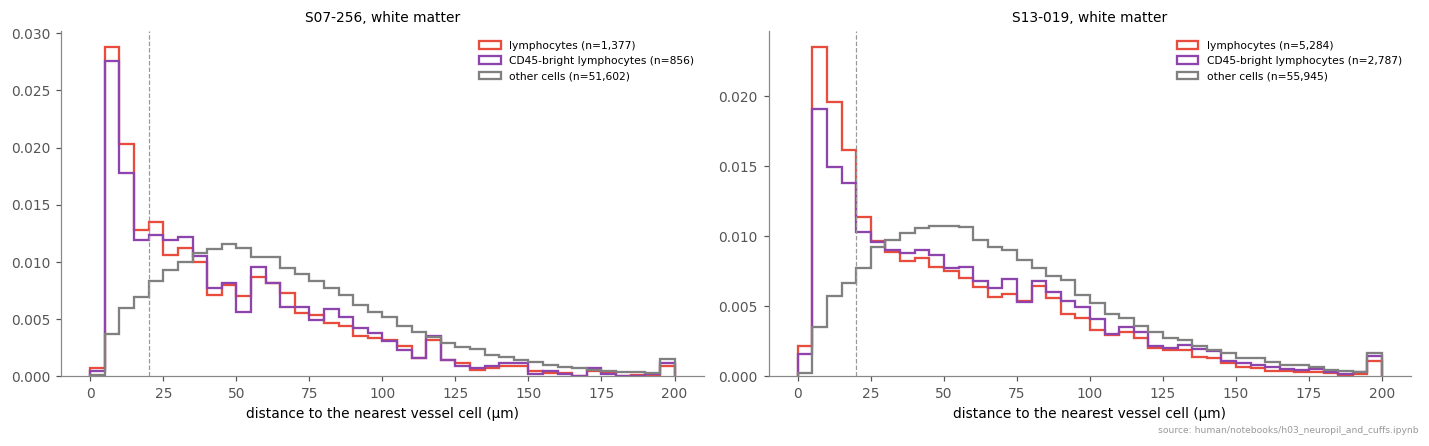

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, smp in zip(axs, MS):
    g = d[(d.sample_id == smp) & d.zone.isin(["myelinated", "partial", "demyelinated"])]
    bins = np.arange(0, 205, 5)
    for lab_, m, colr in [("lymphocytes", g.cell_type == LYMPH, "#e74c3c"),
                          ("CD45-bright lymphocytes", g.cd45_bright, "#8e44ad"),
                          ("other cells", ~g.cell_type.isin(VESSEL + [LYMPH]), "0.5")]:
        ax.hist(g.loc[m, "d_vessel"].clip(upper=200), bins=bins, density=True, histtype="step", lw=1.5, color=colr,
                label=f"{lab_} (n={m.sum():,})")
    ax.axvline(20, color="0.6", ls="--", lw=0.8)
    ax.set_xlabel("distance to the nearest vessel cell (µm)")
    ax.set_title(f"{smp}, white matter", fontsize=9)
    ax.legend(fontsize=7)
fig.tight_layout()
plotting.save_fig(fig, "distance_to_vessels", OUT, SRC)

**Cuffs in the tissue.** Random perivascular lymphocyte clusters (a lymphocyte within 20 µm of a vessel cell with
≥ 5 other lymphocytes within 30 µm; one cluster per random draw, seed 0), 100 µm crops. Left: boundary channel
(CD45 on lymphocytes, ATP1A1 neuropil); middle: αSMA/vimentin (vessel wall); right: DAPI. Lymphocytes outlined
cyan (CD45-bright: thick), vessel cells green.

PosixPath('/Users/christoffer/work/karolinska/development/BeyondBoundaries/human/results/h03_neuropil_and_cuffs/gallery_cuffs.png')

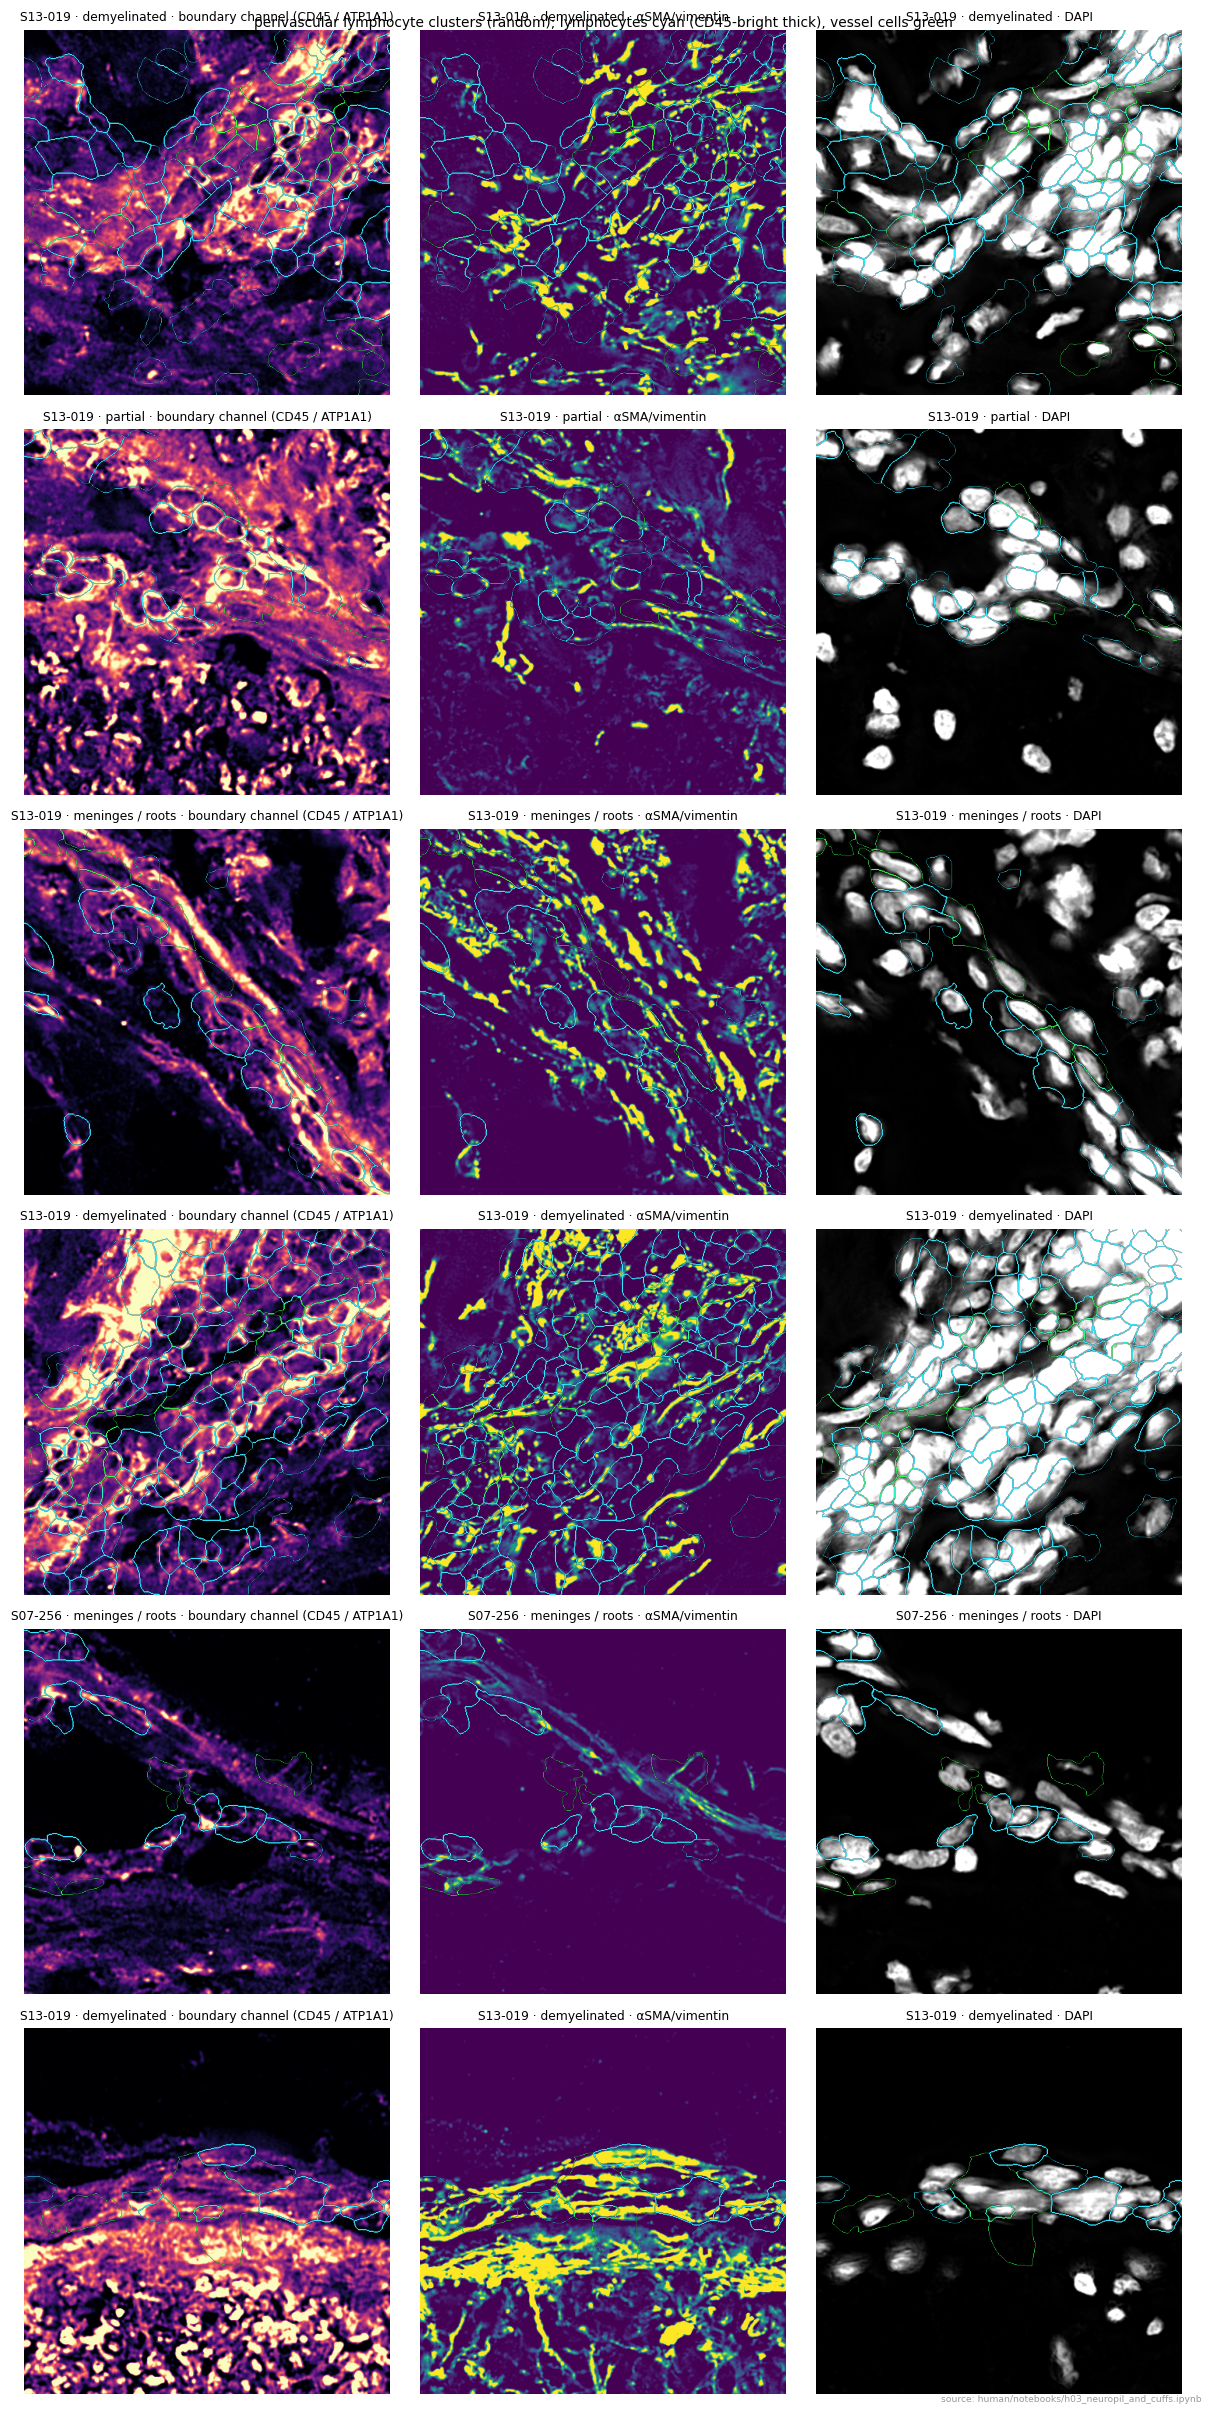

In [6]:
_B, _R = {}, {}


def bundle(smp):
    if smp not in _B:
        _B[smp] = XeniumBundle(bundles[sec_of[smp]])
    return _B[smp]


def drange(smp, ch):
    if (smp, ch) not in _R:
        im = bundle(smp).read_level(ch, 3).astype(np.float32)
        v = im[im > 0]
        _R[(smp, ch)] = (np.percentile(v, 1), np.percentile(v, 99.5))
    return _R[(smp, ch)]


rng = np.random.default_rng(0)
cands = []
for smp in MS:
    g = d[d.sample_id == smp]
    Ly = g[g.cell_type == LYMPH]
    cnt = cKDTree(Ly[["x_centroid", "y_centroid"]].to_numpy()).query_ball_point(Ly[["x_centroid", "y_centroid"]].to_numpy(),
                                                                             30, return_length=True)
    cands.append(Ly[(cnt >= 6) & Ly.perivascular])
cands = pd.concat(cands)
picks = cands.iloc[rng.choice(len(cands), size=min(6, len(cands)), replace=False)] if len(cands) else cands
fig, axs = plt.subplots(len(picks), 3, figsize=(11, 3.7 * len(picks)), squeeze=False)
W = 100
for i, (_, r) in enumerate(picks.iterrows()):
    b = bundle(r.sample_id)
    px = b.pixel_size
    y0, x0 = int(r.centroid_y_px - W / 2 / px), int(r.centroid_x_px - W / 2 / px)
    img, lab, _ = b.read_window(y0, x0, int(W / px), int(W / px))
    near = d[(d.sample_id == r.sample_id) & (d.centroid_x_px.between(x0, x0 + W / px)) & (d.centroid_y_px.between(y0, y0 + W / px))]
    e = find_boundaries(lab, mode="inner")
    ov = np.zeros((*lab.shape, 4))
    ov[e & np.isin(lab, near[near.cell_type.isin(VESSEL)].label.to_numpy())] = (0.2, 1, 0.3, 1)
    ov[e & np.isin(lab, near[near.cell_type == LYMPH].label.to_numpy())] = (0.2, 0.9, 1, 1)
    thick = find_boundaries(np.where(np.isin(lab, near[near.cd45_bright].label.to_numpy()), lab, 0), mode="thick")
    ov[thick] = (0.2, 0.9, 1, 1)
    for j, (ch_i, ch, cm, nm) in enumerate([(1, "bnd", "magma", "boundary channel (CD45 / ATP1A1)"),
                                            (3, "smavim", "viridis", "αSMA/vimentin"), (0, "dapi", "gray", "DAPI")]):
        lo, hi = drange(r.sample_id, ch)
        axs[i, j].imshow(np.clip((img[ch_i] - lo) / (hi - lo), 0, 1), cmap=cm)
        axs[i, j].imshow(ov)
        axs[i, j].set_title(f"{r.sample_id} · {r.zone} · {nm}", fontsize=8)
        axs[i, j].axis("off")
fig.suptitle("perivascular lymphocyte clusters (random); lymphocytes cyan (CD45-bright thick), vessel cells green",
             fontsize=9)
fig.tight_layout()
plotting.save_fig(fig, "gallery_cuffs", OUT, SRC)

## Findings
One donor per section: descriptions of each section, not tests across patients.

> **A. Neuropil loss in demyelinated white matter: inconclusive.** As in mouse, demyelinated white matter lies far
> from grey matter (the outer cord, median 975–1,482 µm) and myelinated white matter close to it (375–551 µm), so the
> section-wide comparison is confounded (and points in opposite directions in the two sections: ×1.42, ×0.87).
> Matched for distance to grey matter (± 25 µm) within 300 µm, only the boundary between the zones can be compared
> (823 and 1,252 cells): ATP1A1 ×0.97 in S07-256 and ×0.76 in S13-019, but the halves of each section disagree
> (×1.20 vs ×0.92; ×0.71 vs ×1.01) and the spread is wide (IQR ×0.5–1.5). DAPI is ×1.3–1.4 (hypercellular
> lesions). No claim for human from these two sections.
>
> **B. Lymphocytes sit around vessels, and the boundary channel shows them as CD45-ringed cuffs.** In white matter
> 19–44 % of lymphocytes lie within 20 µm of a vessel cell against 5–13 % of other cells (enrichment ×1.9–4.9; in
> grey matter ×3.1–3.2). In the images, dense perivascular infiltrates show a honeycomb of bright membrane rings in
> the boundary channel around the lymphocytes, next to vimentin-bright vessel walls. The CD45-bright *share* is
> lower in cuffs than in the parenchyma (S13-019 demyelinated 38 % vs 52 %): in a dense cuff the 2 µm ring around
> each lymphocyte is its bright neighbours, so the rim-vs-ring measure undercounts there — a limit of the measure.